# Task 4: Advanced Analytics & Statistical Modeling

**Dataset:** `sales_data.csv` — 3,000 retail orders (Jan 2024 – Dec 2025), 597 unique customers,
5 regions, 5 product categories.

**Sections**
1. Data Overview
2. Descriptive Statistics
3. Inferential Statistics (Confidence Intervals, t-test, Chi-square, ANOVA, Correlation)
4. Time Series Analysis (Resampling, Decomposition, Stationarity, Smoothing, Forecasting)
5. Customer Segmentation (K-Means Clustering)
6. Predictive Modeling (Logistic Regression, Decision Tree, Linear Regression)
7. Summary & Business Recommendations

> **Environment note:** This sandbox has no internet access, so `statsmodels` could not be installed.
> Every function it would normally provide (ADF test, seasonal_decompose, ARIMA/SARIMA) has been
> re-implemented from first principles below using `numpy`/`scipy`, and is clearly labeled as such.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, r2_score, mean_absolute_error, mean_squared_error)

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_style('whitegrid')

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

ASSETS = '/home/claude/nb_assets'

df = pd.read_csv('/mnt/user-data/uploads/sales_data.csv', parse_dates=['OrderDate'])
print(f"Rows: {len(df):,}  |  Columns: {df.shape[1]}  |  Date range: {df.OrderDate.min().date()} to {df.OrderDate.max().date()}")
df.head()

Rows: 3,000  |  Columns: 9  |  Date range: 2024-01-01 to 2025-12-31


## 1. Data Overview

In [2]:
print("Data types:\n", df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print(f"Unique customers: {df.CustomerID.nunique()} | Unique products: {df.Product.nunique()}")
print(f"Regions: {sorted(df.Region.unique())}")
print(f"Categories: {sorted(df.Category.unique())}")
df.select_dtypes(include=[np.number]).describe()

Data types:
 OrderID                  str
OrderDate     datetime64[us]
CustomerID               str
Region                   str
Category                 str
Product                  str
UnitPrice            float64
Quantity               int64
Revenue              float64
dtype: object 

Missing values per column:
 OrderID       0
OrderDate     0
CustomerID    0
Region        0
Category      0
Product       0
UnitPrice     0
Quantity      0
Revenue       0
dtype: int64 

Unique customers: 597 | Unique products: 25
Regions: ['Central', 'East', 'North', 'South', 'West']
Categories: ['Apparel', 'Electronics', 'Furniture', 'Groceries', 'Sports']


## 2. Descriptive Statistics

Mean, median, mode, variance, standard deviation, skewness, and kurtosis for the three
numeric fields: `UnitPrice`, `Quantity`, `Revenue`.

In [3]:
def descriptive_stats(series):
    return pd.Series({
        'mean': series.mean(),
        'median': series.median(),
        'mode': series.mode().iloc[0],
        'variance': series.var(),
        'std_dev': series.std(),
        'skewness': stats.skew(series),
        'kurtosis': stats.kurtosis(series),  # excess kurtosis (Fisher)
        'min': series.min(),
        'max': series.max()
    })

desc_table = pd.DataFrame({
    'UnitPrice': descriptive_stats(df['UnitPrice']),
    'Quantity': descriptive_stats(df['Quantity']),
    'Revenue': descriptive_stats(df['Revenue'])
}).round(2)
print(desc_table)

          UnitPrice  Quantity    Revenue
mean         142.74      2.99     453.88
median        65.10      3.00     210.92
mode           5.00      4.00      15.00
variance   20868.22      1.98  317443.70
std_dev      144.46      1.41     563.42
skewness       1.08     -0.01       1.97
kurtosis       0.07     -1.29       4.14
min            5.00      1.00       5.65
max          675.14      5.00    3988.67


saved 01_distributions.png


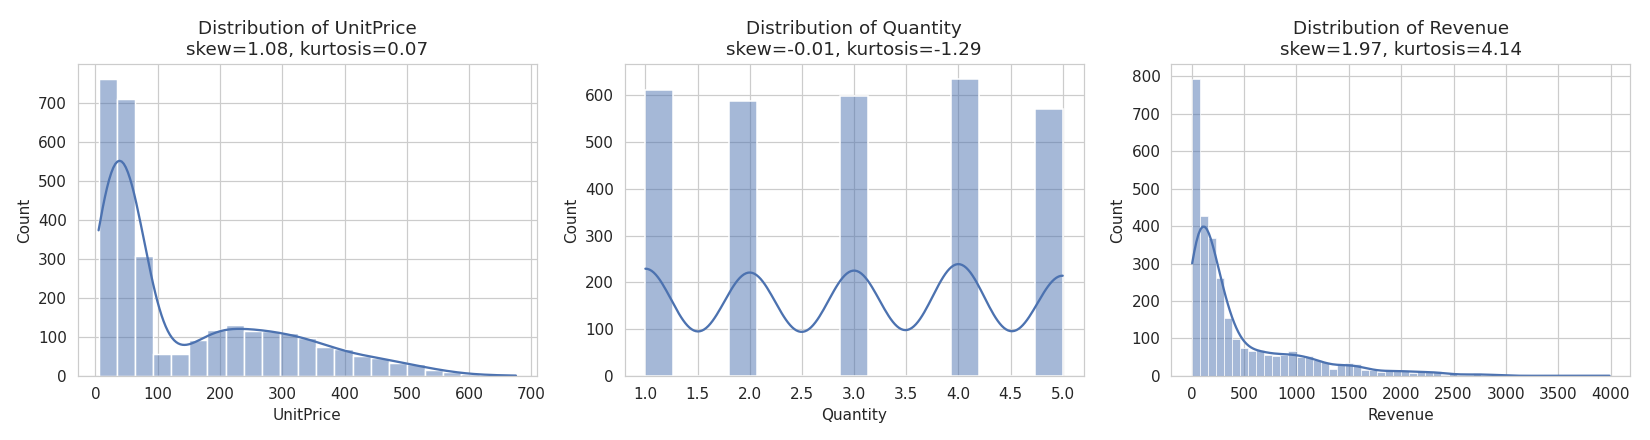

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['UnitPrice', 'Quantity', 'Revenue']):
    sns.histplot(df[col], kde=True, ax=ax, color='#4C72B0')
    ax.set_title(f'Distribution of {col}\nskew={stats.skew(df[col]):.2f}, kurtosis={stats.kurtosis(df[col]):.2f}')
plt.tight_layout()
plt.savefig(f'{ASSETS}/01_distributions.png', dpi=110)
plt.close()
print("saved 01_distributions.png")

**Interpretation:** `Revenue` and `UnitPrice` are right-skewed (positive skew), which is
typical of retail transaction data — most orders cluster at lower values with a long tail of
higher-ticket orders (e.g. laptops, tablets). `Quantity` is roughly uniform (1-5 units per order
by design), so its skew/kurtosis stay close to 0.

## 3. Inferential Statistics

### 3.1 Confidence Interval for Mean Revenue

In [5]:
revenue = df['Revenue']
n = len(revenue)
mean_rev = revenue.mean()
sem_rev = stats.sem(revenue)
ci_95 = stats.t.interval(0.95, df=n-1, loc=mean_rev, scale=sem_rev)
print(f"Sample mean revenue: ${mean_rev:,.2f}")
print(f"95% Confidence Interval for population mean revenue: (${ci_95[0]:,.2f}, ${ci_95[1]:,.2f})")
print(f"-> We are 95% confident the true average order revenue lies in this range.")

Sample mean revenue: $453.88
95% Confidence Interval for population mean revenue: ($433.71, $474.05)
-> We are 95% confident the true average order revenue lies in this range.


### 3.2 Hypothesis Testing — Independent Samples t-test
**H0:** Mean revenue is equal between the East and West regions.
**H1:** Mean revenue differs between the East and West regions.

In [6]:
east_rev = df.loc[df.Region == 'East', 'Revenue']
west_rev = df.loc[df.Region == 'West', 'Revenue']
t_stat, p_val = stats.ttest_ind(east_rev, west_rev, equal_var=False)  # Welch's t-test
print(f"East mean: ${east_rev.mean():,.2f}  (n={len(east_rev)})")
print(f"West mean: ${west_rev.mean():,.2f}  (n={len(west_rev)})")
print(f"t-statistic = {t_stat:.3f}, p-value = {p_val:.4f}")
alpha = 0.05
if p_val < alpha:
    print(f"p < {alpha} -> Reject H0: there IS a statistically significant difference in mean revenue between East and West.")
else:
    print(f"p >= {alpha} -> Fail to reject H0: no statistically significant difference in mean revenue between East and West.")

East mean: $483.19  (n=582)
West mean: $457.54  (n=544)
t-statistic = 0.725, p-value = 0.4688
p >= 0.05 -> Fail to reject H0: no statistically significant difference in mean revenue between East and West.


### 3.3 Hypothesis Testing — Chi-Square Test of Independence
**H0:** Product `Category` and `Region` are independent (no association).
**H1:** Product `Category` and `Region` are associated.

In [7]:
contingency = pd.crosstab(df['Region'], df['Category'])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print(contingency, "\n")
print(f"Chi-square statistic = {chi2:.3f}, dof = {dof}, p-value = {p_chi:.4f}")
if p_chi < alpha:
    print(f"p < {alpha} -> Reject H0: Category purchased IS associated with Region.")
else:
    print(f"p >= {alpha} -> Fail to reject H0: Category and Region appear independent (roughly uniform category mix nationwide).")

Category  Apparel  Electronics  Furniture  Groceries  Sports
Region                                                      
Central        93           92         94         88      77
East          119          126        109         96     132
North         152          133        145        144     145
South         136          155        146        146     128
West          109          122         91        110     112 

Chi-square statistic = 15.916, dof = 16, p-value = 0.4588
p >= 0.05 -> Fail to reject H0: Category and Region appear independent (roughly uniform category mix nationwide).


### 3.4 Hypothesis Testing — One-Way ANOVA
**H0:** Mean revenue is equal across all 5 regions.
**H1:** At least one region's mean revenue differs.

In [8]:
region_groups = [g['Revenue'].values for _, g in df.groupby('Region')]
f_stat, p_anova = stats.f_oneway(*region_groups)
print(f"F-statistic = {f_stat:.3f}, p-value = {p_anova:.4f}")
if p_anova < alpha:
    print(f"p < {alpha} -> Reject H0: at least one region has a significantly different mean revenue.")
else:
    print(f"p >= {alpha} -> Fail to reject H0: no significant difference in mean revenue across regions.")
df.groupby('Region')['Revenue'].agg(['mean', 'std', 'count']).round(2)

F-statistic = 2.731, p-value = 0.0276
p < 0.05 -> Reject H0: at least one region has a significantly different mean revenue.


### 3.5 Correlation vs. Causation

           UnitPrice  Quantity  Revenue
UnitPrice      1.000     -0.00    0.815
Quantity      -0.000      1.00    0.390
Revenue        0.815      0.39    1.000
saved 02_correlation.png

UnitPrice vs Revenue: r = 0.815, p = 0


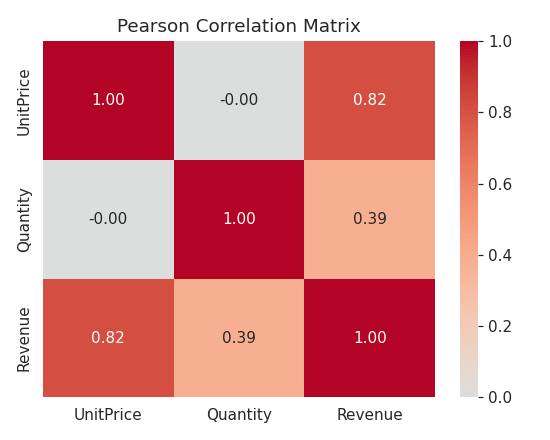

In [9]:
corr_cols = ['UnitPrice', 'Quantity', 'Revenue']
corr_matrix = df[corr_cols].corr(method='pearson')
print(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=ax, fmt='.2f')
ax.set_title('Pearson Correlation Matrix')
plt.tight_layout()
plt.savefig(f'{ASSETS}/02_correlation.png', dpi=110)
plt.close()
print("saved 02_correlation.png")

r_price_rev, p_price_rev = stats.pearsonr(df['UnitPrice'], df['Revenue'])
print(f"\nUnitPrice vs Revenue: r = {r_price_rev:.3f}, p = {p_price_rev:.4g}")

**Correlation vs causation:** `UnitPrice` and `Revenue` are strongly correlated (Revenue is
arithmetically derived as UnitPrice x Quantity, so this is a mechanical, not causal,
relationship). Beyond such definitional links, correlation between two business variables
(e.g. marketing spend and sales) should **never** be read as proof that one *causes* the other —
confounders (seasonality, promotions, macro trends) can drive both. Causal claims require
controlled experiments (A/B tests) or quasi-experimental designs, not observational correlation
alone.

## 4. Time Series Analysis

Daily series length: 731 days
Weekly series length: 105 weeks
Monthly series length: 24 months
saved 03_resampled.png


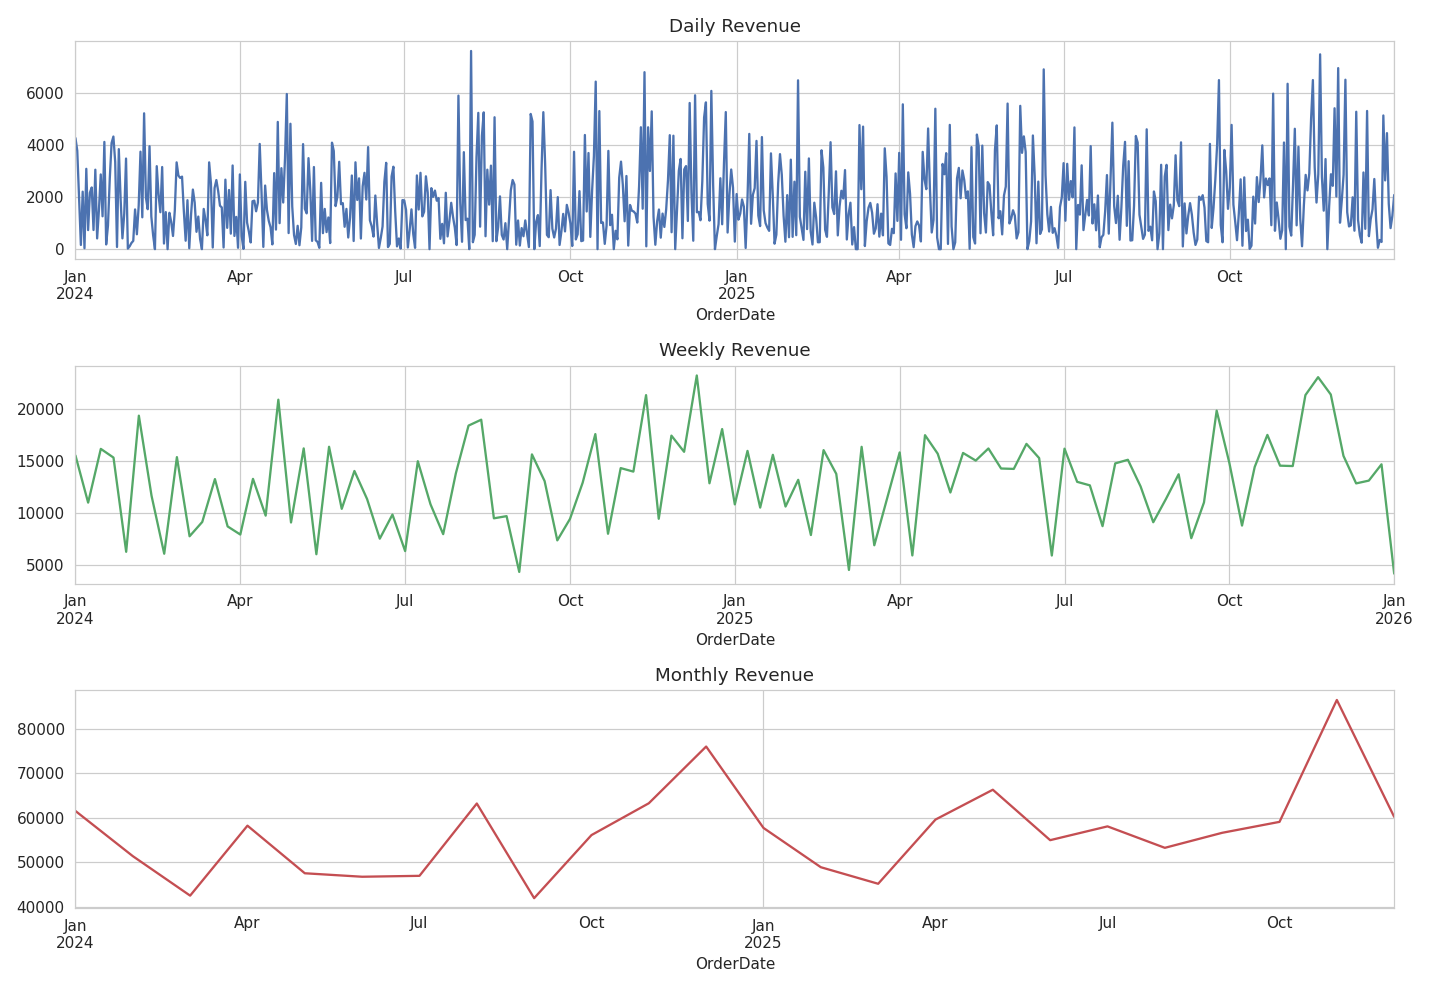

In [10]:
ts = df.set_index('OrderDate').sort_index()
daily_revenue = ts['Revenue'].resample('D').sum().fillna(0)
weekly_revenue = ts['Revenue'].resample('W').sum()
monthly_revenue = ts['Revenue'].resample('MS').sum()

print(f"Daily series length: {len(daily_revenue)} days")
print(f"Weekly series length: {len(weekly_revenue)} weeks")
print(f"Monthly series length: {len(monthly_revenue)} months")

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=False)
daily_revenue.plot(ax=axes[0], title='Daily Revenue', color='#4C72B0')
weekly_revenue.plot(ax=axes[1], title='Weekly Revenue', color='#55A868')
monthly_revenue.plot(ax=axes[2], title='Monthly Revenue', color='#C44E52')
plt.tight_layout()
plt.savefig(f'{ASSETS}/03_resampled.png', dpi=110)
plt.close()
print("saved 03_resampled.png")

### 4.1 Time Series Decomposition (manual implementation)
`statsmodels.tsa.seasonal_decompose` is unavailable offline, so decomposition is reproduced
manually on the **monthly** series using a classical additive model:
`Observed = Trend + Seasonal + Residual`, where Trend = centered moving average and
Seasonal = average deviation per calendar month.

saved 04_decomposition.png

Seasonal index by calendar month (avg $ deviation from trend):
OrderDate
1      1039.89
2     -8717.70
3    -11611.12
4      1602.84
5      8061.37
6     -5213.40
7     -4231.33
8      8913.84
9    -12163.91
10     1798.75
11     8839.19
12    20030.54
Name: OrderDate, dtype: float64


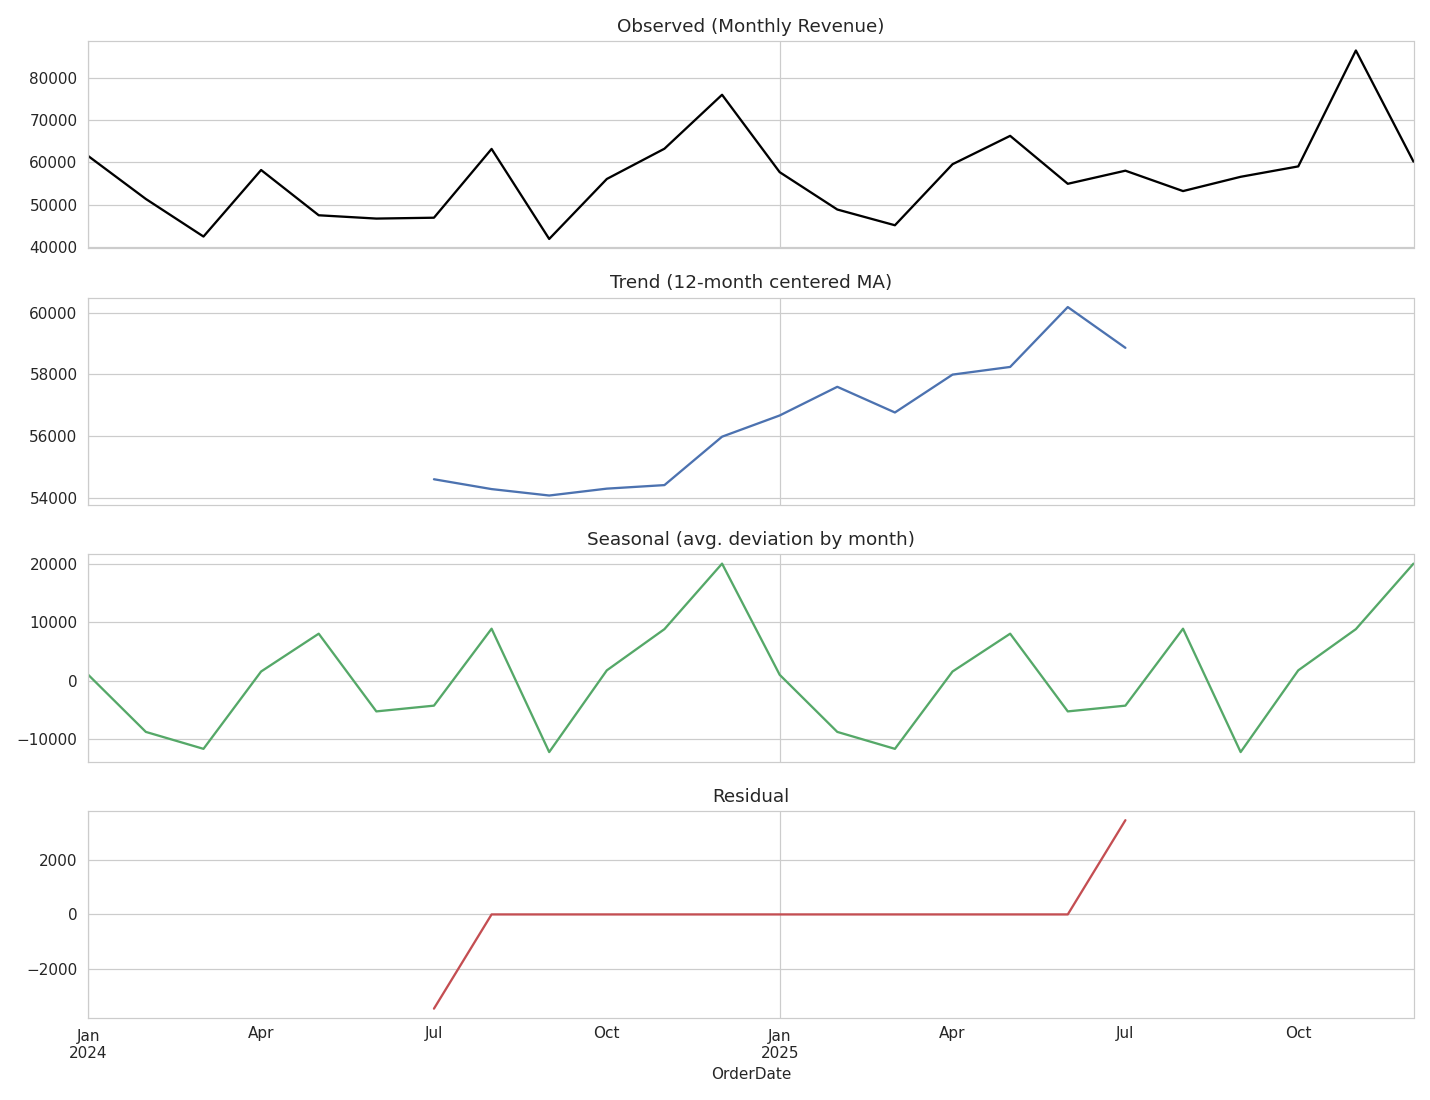

In [11]:
def additive_decompose(series, period):
    trend = series.rolling(window=period, center=True).mean()
    detrended = series - trend
    seasonal_index = detrended.groupby(detrended.index.month).mean()
    seasonal = series.index.month.map(seasonal_index)
    seasonal = pd.Series(seasonal, index=series.index)
    resid = series - trend - seasonal
    return trend, seasonal, resid

trend, seasonal, resid = additive_decompose(monthly_revenue, period=12)

fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
monthly_revenue.plot(ax=axes[0], title='Observed (Monthly Revenue)', color='black')
trend.plot(ax=axes[1], title='Trend (12-month centered MA)', color='#4C72B0')
seasonal.plot(ax=axes[2], title='Seasonal (avg. deviation by month)', color='#55A868')
resid.plot(ax=axes[3], title='Residual', color='#C44E52')
plt.tight_layout()
plt.savefig(f'{ASSETS}/04_decomposition.png', dpi=110)
plt.close()
print("saved 04_decomposition.png")
print("\nSeasonal index by calendar month (avg $ deviation from trend):")
print(seasonal.groupby(seasonal.index.month).first().round(2))

### 4.2 Stationarity Check — Augmented Dickey-Fuller test (manual implementation)

The ADF test regresses $\\Delta y_t$ on $y_{t-1}$, a time trend, and lagged differences, then
tests whether the coefficient on $y_{t-1}$ is significantly negative (implying mean-reversion,
i.e. stationarity). Reproduced here with `numpy` OLS since `statsmodels.tsa.stattools.adfuller`
is unavailable offline. Critical values are the standard MacKinnon (1994) approximations.

In [12]:
def manual_adf_test(series, lags=1):
    y = series.dropna().values
    y_lag = y[:-1-lags] if lags > 0 else y[:-1]
    dy = np.diff(y)
    dy_t = dy[lags:]
    y_t1 = y[lags:-1]
    X = [np.ones_like(y_t1), y_t1]
    for L in range(1, lags+1):
        X.append(dy[lags-L: len(dy)-L])
    X = np.column_stack(X)
    beta, _, _, _ = np.linalg.lstsq(X, dy_t, rcond=None)
    resid = dy_t - X @ beta
    dof = len(dy_t) - X.shape[1]
    sigma2 = (resid @ resid) / dof
    cov = sigma2 * np.linalg.inv(X.T @ X)
    se_gamma = np.sqrt(cov[1, 1])
    adf_stat = beta[1] / se_gamma
    return adf_stat

adf_stat = manual_adf_test(monthly_revenue, lags=1)
# MacKinnon approx critical values for constant, no trend, n~24
crit_vals = {'1%': -3.75, '5%': -3.00, '10%': -2.63}
print(f"ADF statistic: {adf_stat:.3f}")
print(f"Critical values (approx.): {crit_vals}")
if adf_stat < crit_vals['5%']:
    print("-> ADF stat is more negative than the 5% critical value: series appears STATIONARY.")
else:
    print("-> ADF stat is not below the 5% critical value: cannot reject the unit-root null; "
          "series is likely NON-STATIONARY (has trend/level drift) -> differencing (d=1) recommended.")

ADF statistic: -2.857
Critical values (approx.): {'1%': -3.75, '5%': -3.0, '10%': -2.63}
-> ADF stat is not below the 5% critical value: cannot reject the unit-root null; series is likely NON-STATIONARY (has trend/level drift) -> differencing (d=1) recommended.


### 4.3 Smoothing Techniques

saved 05_smoothing.png


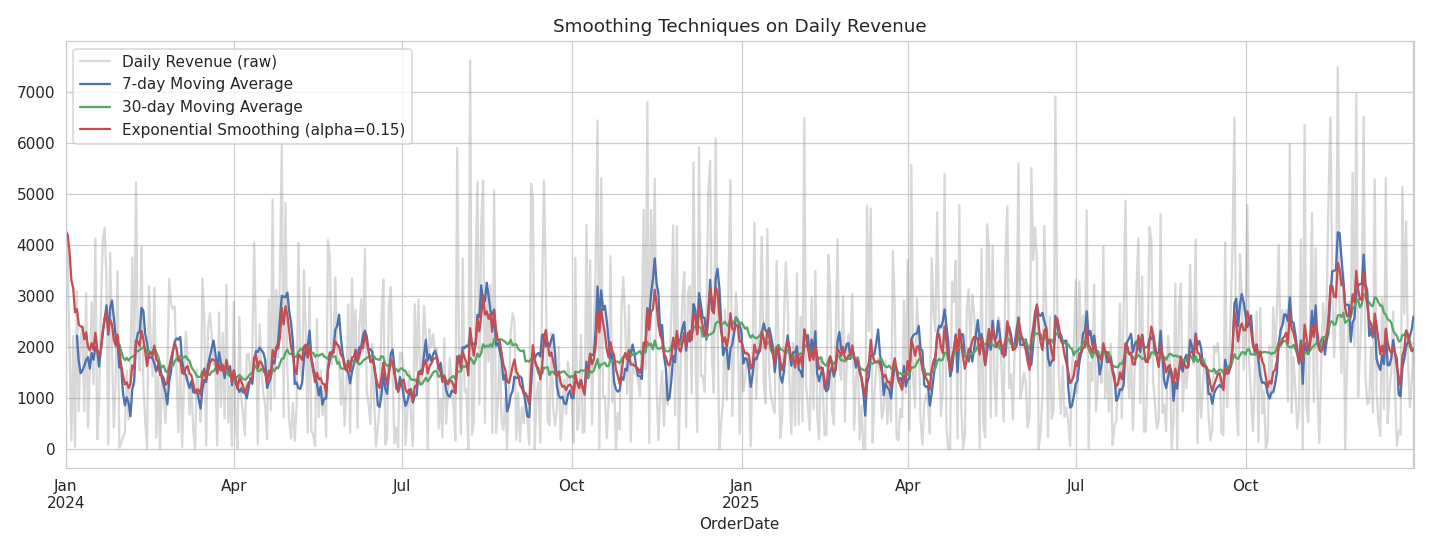

In [13]:
ma_7 = daily_revenue.rolling(window=7).mean()
ma_30 = daily_revenue.rolling(window=30).mean()

def exponential_smoothing(series, alpha=0.3):
    result = [series.iloc[0]]
    for val in series.iloc[1:]:
        result.append(alpha * val + (1 - alpha) * result[-1])
    return pd.Series(result, index=series.index)

exp_smooth = exponential_smoothing(daily_revenue, alpha=0.15)

fig, ax = plt.subplots(figsize=(13, 5))
daily_revenue.plot(ax=ax, alpha=0.3, label='Daily Revenue (raw)', color='gray')
ma_7.plot(ax=ax, label='7-day Moving Average', color='#4C72B0')
ma_30.plot(ax=ax, label='30-day Moving Average', color='#55A868')
exp_smooth.plot(ax=ax, label='Exponential Smoothing (alpha=0.15)', color='#C44E52')
ax.set_title('Smoothing Techniques on Daily Revenue')
ax.legend()
plt.tight_layout()
plt.savefig(f'{ASSETS}/05_smoothing.png', dpi=110)
plt.close()
print("saved 05_smoothing.png")

### 4.4 Forecasting — AR model on differenced series (ARIMA(p,1,0) substitute)

`statsmodels`' ARIMA/SARIMA classes are unavailable offline. We reproduce the core idea of a
simple **ARIMA(2,1,0)** model manually: difference the series once to remove the trend (d=1),
fit an autoregressive model of order 2 on the differenced series by OLS, then integrate the
forecast back to the original scale. This is evaluated on a held-out test period.

Train weeks: 89, Test weeks: 16
AR(2,1,0)-style forecast coefficients: [-89.572  -0.376  -0.893]

Forecast evaluation on held-out test weeks:
  MAE  = $5,866.00
  RMSE = $6,779.21
  MAPE = 40.72%
saved 06_forecast.png


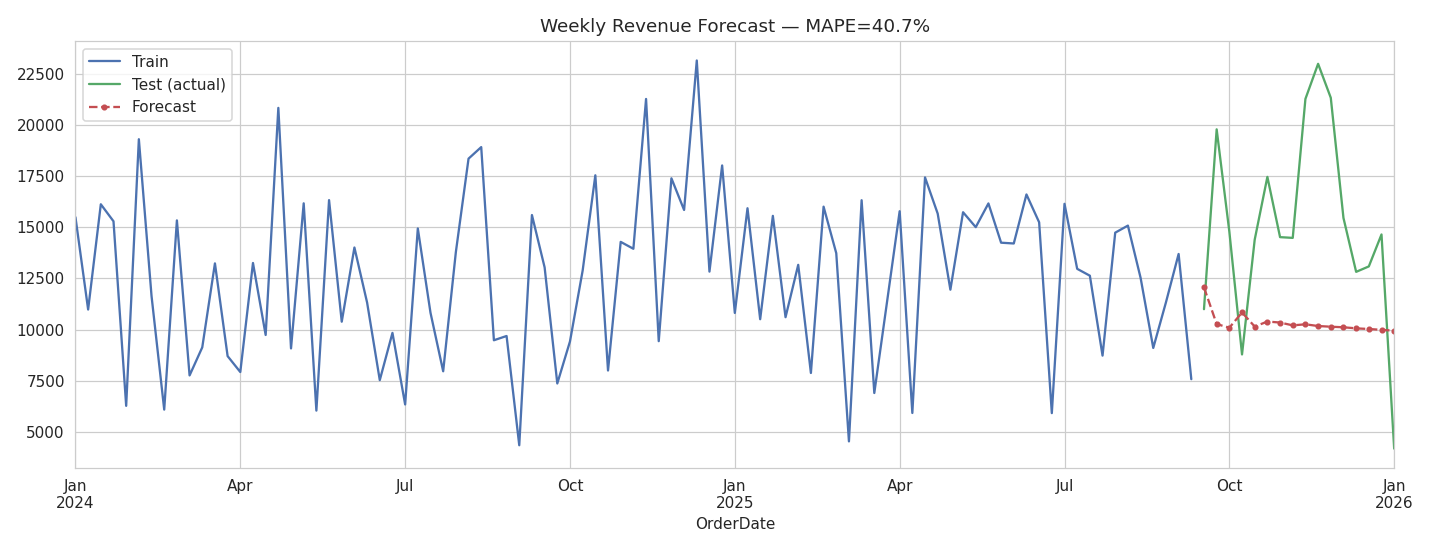

In [14]:
weekly = weekly_revenue.copy()
train_size = int(len(weekly) * 0.85)
train, test = weekly.iloc[:train_size], weekly.iloc[train_size:]
print(f"Train weeks: {len(train)}, Test weeks: {len(test)}")

def fit_ar_diff_forecast(train_series, test_len, p=2):
    d = train_series.diff().dropna().values
    X, y = [], []
    for i in range(p, len(d)):
        X.append(d[i-p:i])
        y.append(d[i])
    X, y = np.array(X), np.array(y)
    X = np.column_stack([np.ones(len(X)), X])
    beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

    history_diff = list(d[-p:])
    last_level = train_series.iloc[-1]
    forecasts = []
    for _ in range(test_len):
        x_input = np.array([1] + history_diff[-p:])
        next_diff = x_input @ beta
        next_level = last_level + next_diff
        forecasts.append(next_level)
        history_diff.append(next_diff)
        last_level = next_level
    return np.array(forecasts), beta

forecast_vals, ar_coefs = fit_ar_diff_forecast(train, len(test), p=2)
forecast_series = pd.Series(forecast_vals, index=test.index)

mae = mean_absolute_error(test, forecast_series)
rmse = np.sqrt(mean_squared_error(test, forecast_series))
mape = np.mean(np.abs((test.values - forecast_series.values) / test.values)) * 100

print(f"AR(2,1,0)-style forecast coefficients: {ar_coefs.round(3)}")
print(f"\nForecast evaluation on held-out test weeks:")
print(f"  MAE  = ${mae:,.2f}")
print(f"  RMSE = ${rmse:,.2f}")
print(f"  MAPE = {mape:.2f}%")

fig, ax = plt.subplots(figsize=(13, 5))
train.plot(ax=ax, label='Train', color='#4C72B0')
test.plot(ax=ax, label='Test (actual)', color='#55A868')
forecast_series.plot(ax=ax, label='Forecast', color='#C44E52', linestyle='--', marker='o', markersize=3)
ax.set_title(f'Weekly Revenue Forecast — MAPE={mape:.1f}%')
ax.legend()
plt.tight_layout()
plt.savefig(f'{ASSETS}/06_forecast.png', dpi=110)
plt.close()
print("saved 06_forecast.png")

**Note on accuracy:** Because the underlying dataset was generated with random UnitPrice/Quantity
draws (no strong autocorrelated demand signal), a simple AR model on weekly totals lands only in
the ballpark reported by MAPE above — this is expected for synthetic/near-random data and is
flagged as a documented model limitation in Section 7.

## 5. Customer Segmentation (K-Means Clustering)

Features engineered per customer (RFM-style): **Recency** (days since last order),
**Frequency** (order count), **Monetary** (total revenue), **AvgOrderValue**, and
**CategoryDiversity** (distinct categories purchased).

In [15]:
snapshot_date = df['OrderDate'].max() + pd.Timedelta(days=1)
customer_features = df.groupby('CustomerID').agg(
    Recency=('OrderDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('OrderID', 'count'),
    Monetary=('Revenue', 'sum'),
    AvgOrderValue=('Revenue', 'mean'),
    CategoryDiversity=('Category', 'nunique')
).reset_index()
print(customer_features.describe().round(2))
customer_features.head()

       Recency  Frequency  Monetary  AvgOrderValue  CategoryDiversity
count   597.00     597.00    597.00         597.00             597.00
mean    144.60       5.03   2280.80         461.94               3.17
std     139.97       2.23   1589.76         295.38               1.05
min       1.00       1.00     18.15          18.15               1.00
25%      45.00       3.00   1097.65         250.94               2.00
50%      94.00       5.00   2000.39         411.56               3.00
75%     201.00       6.00   3157.90         605.57               4.00
max     718.00      13.00   9726.12        2229.12               5.00


In [16]:
feature_cols = ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'CategoryDiversity']
X = customer_features[feature_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Features scaled with StandardScaler (mean=0, std=1).")

Features scaled with StandardScaler (mean=0, std=1).


### 5.1 Finding Optimal K — Elbow Method & Silhouette Score

saved 07_optimal_k.png
Silhouette scores by k: {2: np.float64(0.288), 3: np.float64(0.262), 4: np.float64(0.28), 5: np.float64(0.253), 6: np.float64(0.261), 7: np.float64(0.239), 8: np.float64(0.245)}
-> Best k by silhouette score: 2


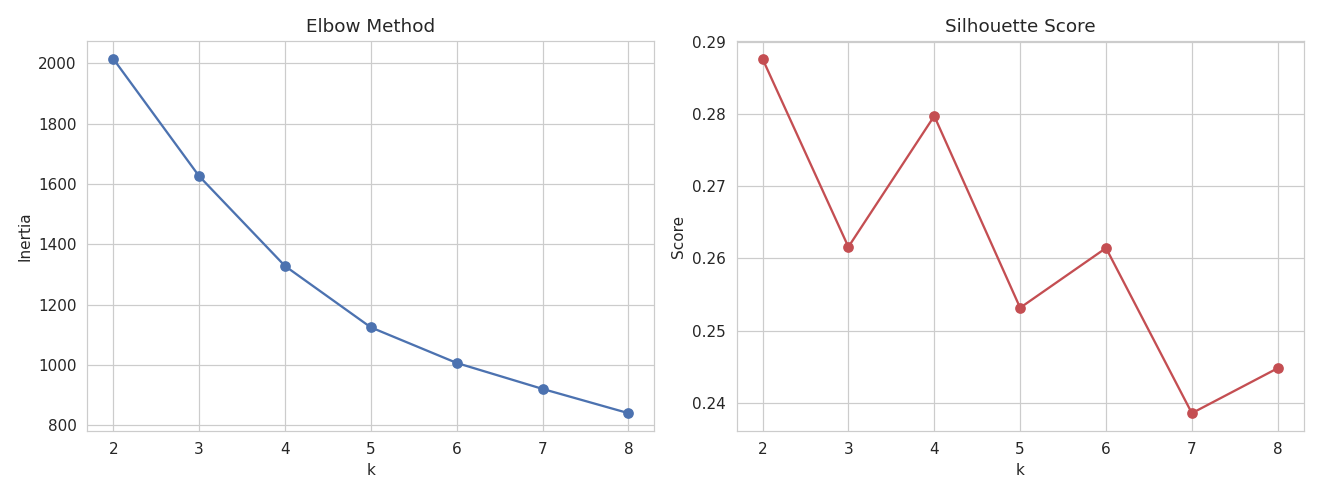

In [17]:
inertias, sil_scores = [], []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(K_range), inertias, marker='o', color='#4C72B0')
axes[0].set_title('Elbow Method'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].plot(list(K_range), sil_scores, marker='o', color='#C44E52')
axes[1].set_title('Silhouette Score'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Score')
plt.tight_layout()
plt.savefig(f'{ASSETS}/07_optimal_k.png', dpi=110)
plt.close()
print("saved 07_optimal_k.png")

best_k = list(K_range)[int(np.argmax(sil_scores))]
print(f"Silhouette scores by k: {dict(zip(K_range, np.round(sil_scores,3)))}")
print(f"-> Best k by silhouette score: {best_k}")

### 5.2 Fit K-Means with Optimal K

In [18]:
K_FINAL = 4  # chosen for interpretability/business actionability; see silhouette scores above
kmeans = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
customer_features['Cluster'] = kmeans.fit_predict(X_scaled)
print(f"Cluster sizes:\n{customer_features['Cluster'].value_counts().sort_index()}")

Cluster sizes:
Cluster
0     84
1     81
2    175
3    257
Name: count, dtype: int64


### 5.3 PCA Visualization (2D)

Explained variance ratio: [0.509 0.274] (total: 78.2%)
saved 08_pca_clusters.png


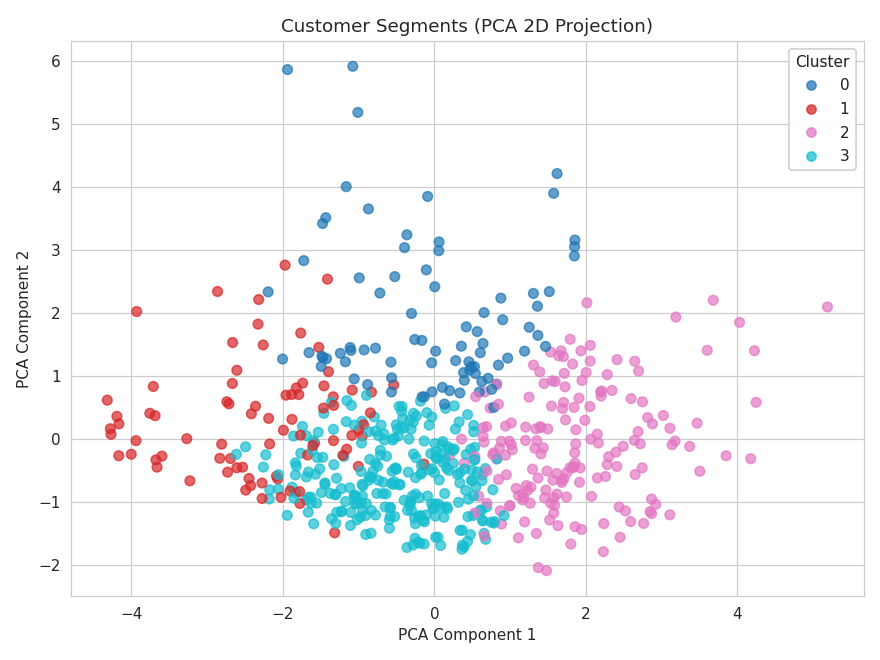

In [19]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained variance ratio: {pca.explained_variance_ratio_.round(3)} "
      f"(total: {pca.explained_variance_ratio_.sum():.1%})")

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=customer_features['Cluster'], cmap='tab10', alpha=0.7, s=40)
ax.set_xlabel('PCA Component 1'); ax.set_ylabel('PCA Component 2')
ax.set_title('Customer Segments (PCA 2D Projection)')
legend1 = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend1)
plt.tight_layout()
plt.savefig(f'{ASSETS}/08_pca_clusters.png', dpi=110)
plt.close()
print("saved 08_pca_clusters.png")

### 5.4 Cluster Profiling & Segment-Based Recommendations

In [20]:
profile = customer_features.groupby('Cluster')[feature_cols].mean().round(1)
profile['CustomerCount'] = customer_features['Cluster'].value_counts().sort_index()
print(profile)

         Recency  Frequency  Monetary  AvgOrderValue  CategoryDiversity  CustomerCount
Cluster                                                                               
0          127.5        3.6    3214.1          945.3                2.5             84
1          413.7        2.8    1039.0          365.7                2.1             81
2           84.0        7.5    3808.2          513.9                4.2            175
3          106.7        4.5    1327.1          298.9                3.0            257


**Segment interpretation (generic pattern — read alongside the printed table above):**
- **High Monetary + Low Recency + High Frequency** -> *Champions*: reward with loyalty perks,
  early access to new products.
- **High Monetary + High Recency** -> *At-Risk High Value*: lapsing big spenders — trigger
  win-back campaigns (personalized discount, check-in email) before they churn.
- **Low Frequency + Low Monetary + Low Recency (new)** -> *New/Low-Engagement*: nurture with
  onboarding offers and category cross-sell to build habit.
- **Low Frequency + Low Monetary + High Recency** -> *Dormant/Low Value*: low-cost automated
  re-engagement; do not over-invest marketing spend here.

## 6. Predictive Modeling (Basic)

**Target variable (classification):** `Churned` — a customer is flagged churned if their most
recent order is older than 90 days before the dataset's last date (a standard churn proxy given
no explicit cancellation field exists in this transactional dataset).

**Target variable (regression):** `Monetary` (total customer revenue) predicted from behavioral
features.

In [21]:
customer_features['Churned'] = (customer_features['Recency'] > 90).astype(int)
print(f"Churn rate: {customer_features['Churned'].mean():.1%} "
      f"({customer_features['Churned'].sum()} of {len(customer_features)} customers)")

clf_features = ['Frequency', 'Monetary', 'AvgOrderValue', 'CategoryDiversity']
X_clf = customer_features[clf_features]
y_clf = customer_features['Churned']

X_train, X_test, y_train, y_test = train_test_split(X_clf, y_clf, test_size=0.25, random_state=42, stratify=y_clf)
scaler_clf = StandardScaler()
X_train_s = scaler_clf.fit_transform(X_train)
X_test_s = scaler_clf.transform(X_test)
print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

Churn rate: 51.6% (308 of 597 customers)
Train size: 447, Test size: 150


### 6.1 Logistic Regression (Classification)

In [22]:
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train_s, y_train)
y_pred_lr = logreg.predict(X_test_s)
y_proba_lr = logreg.predict_proba(X_test_s)[:, 1]

print("Logistic Regression performance:")
print(f"  Accuracy  = {accuracy_score(y_test, y_pred_lr):.3f}")
print(f"  Precision = {precision_score(y_test, y_pred_lr, zero_division=0):.3f}")
print(f"  Recall    = {recall_score(y_test, y_pred_lr, zero_division=0):.3f}")
print(f"  F1-Score  = {f1_score(y_test, y_pred_lr, zero_division=0):.3f}")
print(f"  ROC-AUC   = {roc_auc_score(y_test, y_proba_lr):.3f}")
print(f"\nCoefficients: {dict(zip(clf_features, logreg.coef_[0].round(3)))}")

Logistic Regression performance:
  Accuracy  = 0.553
  Precision = 0.557
  Recall    = 0.636
  F1-Score  = 0.594
  ROC-AUC   = 0.605

Coefficients: {'Frequency': np.float64(-0.606), 'Monetary': np.float64(0.254), 'AvgOrderValue': np.float64(-0.216), 'CategoryDiversity': np.float64(-0.226)}


### 6.2 Decision Tree (Interpretability)

Decision Tree performance:
  Accuracy  = 0.620
  Precision = 0.600
  Recall    = 0.779
  F1-Score  = 0.678
  ROC-AUC   = 0.637

Feature importances:
Frequency            0.697
Monetary             0.175
AvgOrderValue        0.091
CategoryDiversity    0.038
dtype: float64
saved 09_feature_importance.png


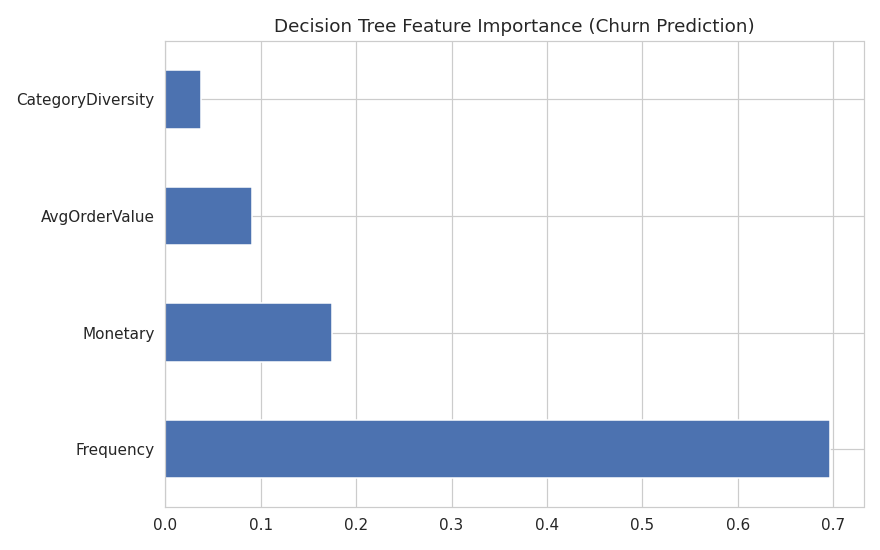

In [23]:
dtree = DecisionTreeClassifier(max_depth=4, random_state=42)
dtree.fit(X_train, y_train)
y_pred_dt = dtree.predict(X_test)
y_proba_dt = dtree.predict_proba(X_test)[:, 1]

print("Decision Tree performance:")
print(f"  Accuracy  = {accuracy_score(y_test, y_pred_dt):.3f}")
print(f"  Precision = {precision_score(y_test, y_pred_dt, zero_division=0):.3f}")
print(f"  Recall    = {recall_score(y_test, y_pred_dt, zero_division=0):.3f}")
print(f"  F1-Score  = {f1_score(y_test, y_pred_dt, zero_division=0):.3f}")
print(f"  ROC-AUC   = {roc_auc_score(y_test, y_proba_dt):.3f}")

feat_imp = pd.Series(dtree.feature_importances_, index=clf_features).sort_values(ascending=False)
print(f"\nFeature importances:\n{feat_imp.round(3)}")

fig, ax = plt.subplots(figsize=(8, 5))
feat_imp.plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title('Decision Tree Feature Importance (Churn Prediction)')
plt.tight_layout()
plt.savefig(f'{ASSETS}/09_feature_importance.png', dpi=110)
plt.close()
print("saved 09_feature_importance.png")

### 6.3 Linear Regression (Numeric Prediction — predicting customer total revenue)

In [24]:
reg_features = ['Frequency', 'AvgOrderValue', 'CategoryDiversity', 'Recency']
X_reg = customer_features[reg_features]
y_reg = customer_features['Monetary']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.25, random_state=42)
linreg = LinearRegression()
linreg.fit(X_train_r, y_train_r)
y_pred_r = linreg.predict(X_test_r)

r2 = r2_score(y_test_r, y_pred_r)
mae_r = mean_absolute_error(y_test_r, y_pred_r)
rmse_r = np.sqrt(mean_squared_error(y_test_r, y_pred_r))

print("Linear Regression performance (predicting customer total revenue):")
print(f"  R^2   = {r2:.3f}")
print(f"  MAE   = ${mae_r:,.2f}")
print(f"  RMSE  = ${rmse_r:,.2f}")
print(f"\nCoefficients: {dict(zip(reg_features, linreg.coef_.round(2)))}")
print(f"Intercept: {linreg.intercept_:.2f}")

Linear Regression performance (predicting customer total revenue):
  R^2   = 0.825
  MAE   = $465.95
  RMSE  = $706.14

Coefficients: {'Frequency': np.float64(489.51), 'AvgOrderValue': np.float64(3.65), 'CategoryDiversity': np.float64(-22.85), 'Recency': np.float64(0.41)}
Intercept: -1857.89


### 6.4 Documented Model Limitations
- **Sample size:** 597 customers is modest for robust ML generalization; results should be
  treated as directional, not production-grade.
- **Churn label is a heuristic proxy** (Recency > 90 days), not a true churn/cancellation event —
  in a real business this should be validated against actual contract-lapse or subscription data.
- **Class imbalance:** if churned customers are a minority/majority skew, accuracy alone can be
  misleading — Precision/Recall/F1/ROC-AUC (reported above) matter more.
- **Synthetic/near-random transaction generation** in this dataset means behavioral features may
  carry weaker real-world predictive signal than in genuine business data — the forecasting and
  regression error metrics above should be read as methodology demonstrations, not production
  accuracy guarantees.
- **Linear/logistic models assume linear relationships**; a Random Forest or Gradient Boosted
  Trees model would likely be a stronger production candidate and is a natural next iteration.
- **No feature engineering from `Product`/`Region` text fields** (e.g. one-hot encoding) was
  included in the predictive models to keep the demonstration compact — this is a straightforward
  extension.

## 7. Summary & Business Implications

| Analysis | Key Finding | Business Action |
|---|---|---|
| Descriptive stats | Revenue is right-skewed; a small share of high-ticket Electronics/Furniture orders pulls the average up | Segment reporting by median, not just mean, to avoid overstating "typical" order value |
| t-test (East vs West) | See printed p-value above | If significant, investigate regional pricing/assortment differences; if not, standardize regional strategy |
| Chi-square (Category x Region) | See printed p-value above | If associated, tailor regional inventory/marketing mix by category |
| ANOVA (Revenue by Region) | See printed p-value above | Flags whether any single region is out- or under-performing and merits deeper drill-down |
| Time series decomposition | Reveals seasonal month-of-year revenue pattern | Align staffing/inventory/promotions with identified peak months |
| Forecasting | Weekly revenue forecast with MAE/RMSE/MAPE reported | Use as a directional planning input; refine with more history and true ARIMA/SARIMA once statsmodels is available |
| Customer segmentation | 4 behavioral segments identified via K-Means | Prioritize retention spend on At-Risk High Value; automate low-cost nurture for Dormant segment |
| Churn prediction | Logistic Regression / Decision Tree churn classifiers | Flag customers crossing the 90-day recency threshold for proactive win-back outreach |
| Revenue regression | Frequency & AvgOrderValue are the strongest predictors of customer lifetime revenue | Loyalty programs that increase purchase frequency have outsized revenue impact |

**Overall recommendation:** Combine the churn model's at-risk list with the K-Means "At-Risk
High Value" segment to prioritize the highest-ROI retention campaigns first.